# Gradient Boosting — Detección de fraude (Caso 1)

Se importan las librerías y la configuración compartida desde comun.py.

In [1]:
import sys
sys.path.append("..")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import confusion_matrix, precision_recall_curve, average_precision_score
from comun.comun import (RANDOM_STATE, CV, SCORING, cargar_train, make_prep,
                         guardar, resumen_cv, guardar_resultados)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)

Se carga el conjunto de entrenamiento con las 15 predictoras finales.

In [2]:
X, y = cargar_train()
print(f"X: {X.shape[0]:,} filas x {X.shape[1]} predictoras | fraudes: {y.sum()} ({y.mean()*100:.3f}%)")

X: 40,000 filas x 15 predictoras | fraudes: 727 (1.818%)


## 1. Pipeline

Se arma el pipeline con One-Hot sin escalado y HistGradientBoostingClassifier, la implementación de Gradient Boosting de scikit-learn que admite class_weight (GradientBoostingClassifier no lo admite) y es mucho más rápida; se desactiva la parada temprana para que todos los folds entrenen igual.

In [3]:
pipe = Pipeline([
    ("prep", make_prep(escalar=False)),
    ("modelo", HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE)),
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{tra

## 2. Validación cruzada y ajuste de hiperparámetros

Se buscan la tasa de aprendizaje, el número de iteraciones, la profundidad, el mínimo de transacciones por hoja y la regularización L2, con peso de fraude ×10 (el que ganó en el árbol y en Random Forest), mediante validación cruzada estratificada de 5 folds sobre train, registrando también el rendimiento en entrenamiento para detectar sobreajuste.

In [4]:
grid = GridSearchCV(pipe, {"modelo__learning_rate": [0.03, 0.1],
                           "modelo__max_iter": [200, 400],
                           "modelo__max_depth": [2, 3, 4],
                           "modelo__min_samples_leaf": [50, 100],
                           "modelo__l2_regularization": [0.0, 1.0],
                           "modelo__class_weight": [{0: 1, 1: 10}]},
                    cv=CV, scoring=SCORING, refit="pr_auc", return_train_score=True, n_jobs=-1)
grid.fit(X, y)
print(f"Mejores parámetros: {grid.best_params_} | PR-AUC CV: {grid.best_score_:.4f}")

Mejores parámetros: {'modelo__class_weight': {0: 1, 1: 10}, 'modelo__l2_regularization': 0.0, 'modelo__learning_rate': 0.03, 'modelo__max_depth': 2, 'modelo__max_iter': 400, 'modelo__min_samples_leaf': 50} | PR-AUC CV: 0.0585


Se muestran las 10 mejores combinaciones según PR-AUC, con el rendimiento en entrenamiento y validación y el cociente entre ambos como medida de sobreajuste.

In [5]:
cvr = pd.DataFrame(grid.cv_results_)
(cvr.assign(lr=cvr["param_modelo__learning_rate"], iteraciones=cvr["param_modelo__max_iter"],
            profundidad=cvr["param_modelo__max_depth"], hoja=cvr["param_modelo__min_samples_leaf"],
            l2=cvr["param_modelo__l2_regularization"],
            sobreajuste=cvr["mean_train_pr_auc"] / cvr["mean_test_pr_auc"])
    .set_index(["lr", "iteraciones", "profundidad", "hoja", "l2"])
    [["mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "sobreajuste", "mean_test_roc_auc"]]
    .rename(columns=lambda c: c.replace("mean_", "").replace("test_", "val_"))
    .sort_values("val_pr_auc", ascending=False).head(10))

train_pr_auc  val_pr_auc  \
lr     iteraciones profundidad hoja l2                                 
0.0300 400         2           50   0.0000        0.0893      0.0585   
                                    1.0000        0.0892      0.0577   
                               100  0.0000        0.0877      0.0565   
       200         2           50   1.0000        0.0767      0.0564   
0.1000 200         2           50   1.0000        0.1051      0.0561   
0.0300 200         2           50   0.0000        0.0766      0.0560   
       400         2           100  1.0000        0.0871      0.0559   
0.1000 200         2           50   0.0000        0.1061      0.0544   
0.0300 200         2           100  0.0000        0.0758      0.0541   
0.1000 200         2           100  0.0000        0.1020      0.0538   

                                            std_val_pr_auc  sobreajuste  \
lr     iteraciones profundidad hoja l2                                    
0.0300 400         2           50   0.0000          0.0055       1.5264   
                                    1.0000          0.0043       1.5469   
                               100  0.0000          0.0054       1.5528   
       200         2           50   1.0000          0.0050       1.3591   
0.1000 200         2           50   1.0000          0.0051       1.8753   
0.0300 200         2           50   0.0000          0.0057       1.3679   
       400         2           100  1.0000          0.0039       1.5582   
0.1000 200         2           50   0.0000          0.0033       1.9512   
0.0300 200         2           100  0.0000          0.0045       1.3999   
0.1000 200         2           100  0.0000          0.0039       1.8973   

                                            val_roc_auc  
lr     iteraciones profundidad hoja l2                   
0.0300 400         2           50   0.0000       0.7000  
                                    1.0000       0.6998  
                               100  0.0000       0.6993  
       200         2           50   1.0000       0.7012  
0.1000 200         2           50   1.0000       0.6924  
0.0300 200         2           50   0.0000       0.7007  
       400         2           100  1.0000       0.6992  
0.1000 200         2           50   0.0000       0.6912  
0.0300 200         2           100  0.0000       0.7012  
0.1000 200         2           100  0.0000       0.6903

Se resumen las métricas del mejor Gradient Boosting como media y desviación estándar de los 5 folds.

In [6]:
resumen = resumen_cv(grid)
resumen

,media,std
métrica,,
precision,0.1393,0.0275
recall,0.0454,0.0111
f1,0.0681,0.0149
roc_auc,0.7000,0.0217
pr_auc,0.0585,0.0055


## 3. Predicciones fuera de fold

Se obtienen probabilidades fuera de fold sobre train y se elige el umbral que maximiza F1, sin tocar el test.

In [7]:
oof = cross_val_predict(grid.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, umb = precision_recall_curve(y, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
k = f1[:-1].argmax()
umbral = umb[k]
pred = (oof >= umbral).astype(int)
print(f"Valores distintos de probabilidad: {np.unique(oof).size:,} | Umbral óptimo F1: {umbral:.3f} | "
      f"alertas: {pred.mean()*100:.1f}% de las transacciones")

Valores distintos de probabilidad: 38,994 | Umbral óptimo F1: 0.358 | alertas: 2.9% de las transacciones


Se grafica la matriz de confusión fuera de fold con el umbral óptimo de F1.

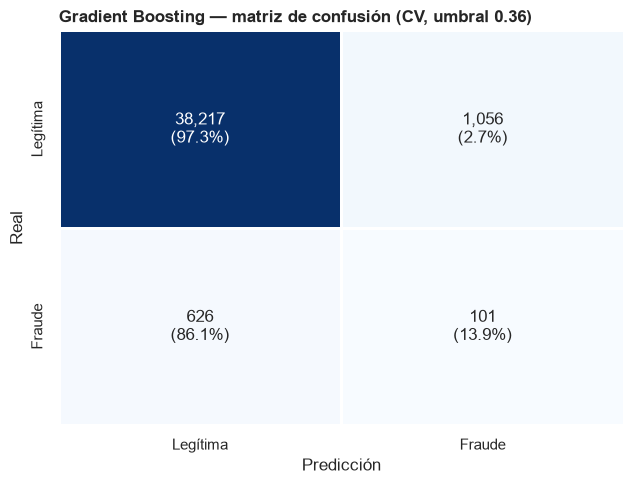

In [8]:
cm = confusion_matrix(y, pred)
etiquetas = np.array([[f"{v:,}\n({v / fila.sum() * 100:.1f}%)" for v in fila] for fila in cm])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=etiquetas, fmt="", cmap="Blues", cbar=False, linewidths=1,
            xticklabels=["Legítima", "Fraude"], yticklabels=["Legítima", "Fraude"], ax=ax)
ax.set(xlabel="Predicción", ylabel="Real")
ax.set_title(f"Gradient Boosting — matriz de confusión (CV, umbral {umbral:.2f})", loc="left", fontweight="bold")
guardar("gb_matriz_confusion")

Se presenta la matriz de confusión en formato de tabla con los conteos de cada caso.

In [9]:
pd.DataFrame(cm, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,38217,1056
Fraude,626,101


Se calculan la precisión, la sensibilidad (recall) y el F1-score de la clase fraude con el umbral óptimo.

In [10]:
tn, fp, fn, tp = cm.ravel()
pd.DataFrame({"valor": {"Umbral": umbral,
                        "Precision = VP / (VP + FP)": tp / (tp + fp),
                        "Sensibilidad (Recall) = VP / (VP + FN)": tp / (tp + fn),
                        "F1-score = 2·VP / (2·VP + FP + FN)": 2 * tp / (2 * tp + fp + fn)}})

,valor
Umbral,0.3584
Precision = VP / (VP + FP),0.0873
Sensibilidad (Recall) = VP / (VP + FN),0.1389
F1-score = 2·VP / (2·VP + FP + FN),0.1072


## 4. Curva Precision-Recall y capacidad de revisión

Se grafica la curva Precision-Recall fuera de fold frente a la línea base de un clasificador aleatorio, marcando el umbral óptimo.

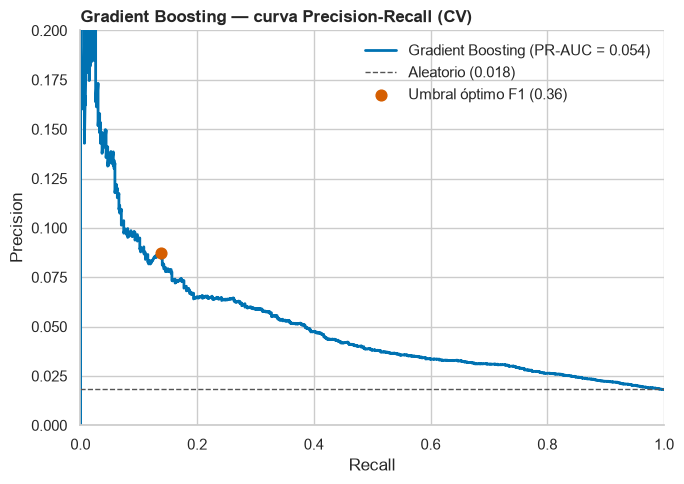

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(x=rec, y=prec, estimator=None, sort=False, color="#0072B2", lw=2,
             label=f"Gradient Boosting (PR-AUC = {average_precision_score(y, oof):.3f})", ax=ax)
ax.axhline(y.mean(), ls="--", color="#555", lw=1, label=f"Aleatorio ({y.mean():.3f})")
ax.scatter(rec[k], prec[k], color="#D55E00", s=60, zorder=3, label=f"Umbral óptimo F1 ({umbral:.2f})")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 0.2))
ax.set_title("Gradient Boosting — curva Precision-Recall (CV)", loc="left", fontweight="bold")
ax.legend(frameon=False)
sns.despine()
guardar("gb_curva_pr")

Se calcula cuántos fraudes se detectarían si el equipo antifraude revisara solo el porcentaje de transacciones con mayor probabilidad de fraude.

In [12]:
yv = y.values
filas = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(oof, 1 - pct / 100)
    alerta = oof >= u
    tp_ = (alerta & (yv == 1)).sum()
    filas.append({"% revisado": pct, "umbral": u, "fraudes detectados": tp_,
                  "recall": tp_ / yv.sum(), "precision": tp_ / alerta.sum()})
pd.DataFrame(filas).set_index("% revisado")

,umbral,fraudes detectados,recall,precision
% revisado,,,,
1,0.4580,47,0.0646,0.1175
2,0.3922,74,0.1018,0.0925
5,0.3156,136,0.1871,0.0680
10,0.2515,231,0.3177,0.0578
20,0.1930,334,0.4594,0.0418
30,0.1610,419,0.5763,0.0349


## 5. Versión mejorada

El mejor modelo quedó en el borde de la búsqueda (profundidad 2, la menor probada, y tasa de aprendizaje 0.03 con 400 iteraciones); se prueban árboles de profundidad 1 (tocones), que no combinan variables entre sí: si rinden igual o mejor, la señal es aditiva, es decir, cada variable aporta por separado y no hay interacciones que aprender.

In [13]:
grid_v2 = GridSearchCV(pipe, {"modelo__max_depth": [1, 2],
                              "modelo__learning_rate": [0.01, 0.03],
                              "modelo__max_iter": [400, 800, 1200],
                              "modelo__min_samples_leaf": [50],
                              "modelo__class_weight": [{0: 1, 1: 10}]},
                       cv=CV, scoring=SCORING, refit="pr_auc", return_train_score=True, n_jobs=-1)
grid_v2.fit(X, y)
print(f"Mejores parámetros: {grid_v2.best_params_} | PR-AUC CV: {grid_v2.best_score_:.4f}")

Mejores parámetros: {'modelo__class_weight': {0: 1, 1: 10}, 'modelo__learning_rate': 0.03, 'modelo__max_depth': 1, 'modelo__max_iter': 400, 'modelo__min_samples_leaf': 50} | PR-AUC CV: 0.0619


Se muestran las combinaciones de la versión mejorada con su PR-AUC en entrenamiento y validación y el cociente de sobreajuste.

In [14]:
cv2 = pd.DataFrame(grid_v2.cv_results_)
(cv2.assign(profundidad=cv2["param_modelo__max_depth"], lr=cv2["param_modelo__learning_rate"],
            iteraciones=cv2["param_modelo__max_iter"],
            sobreajuste=cv2["mean_train_pr_auc"] / cv2["mean_test_pr_auc"])
    .set_index(["profundidad", "lr", "iteraciones"])
    [["mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "sobreajuste", "mean_test_roc_auc"]]
    .rename(columns=lambda c: c.replace("mean_", "").replace("test_", "val_"))
    .sort_values("val_pr_auc", ascending=False))

train_pr_auc  val_pr_auc  std_val_pr_auc  \
profundidad lr     iteraciones                                             
1           0.0300 400                0.0662      0.0619          0.0067   
            0.0100 1200               0.0662      0.0617          0.0064   
                   800                0.0636      0.0607          0.0061   
            0.0300 800                0.0685      0.0605          0.0059   
                   1200               0.0699      0.0603          0.0063   
2           0.0300 400                0.0893      0.0585          0.0055   
            0.0100 800                0.0814      0.0580          0.0054   
                   1200               0.0894      0.0578          0.0055   
                   400                0.0705      0.0550          0.0054   
            0.0300 800                0.1129      0.0548          0.0049   
1           0.0100 400                0.0585      0.0543          0.0049   
2           0.0300 1200               0.1322      0.0521          0.0060   

                                sobreajuste  val_roc_auc  
profundidad lr     iteraciones                            
1           0.0300 400               1.0686       0.7062  
            0.0100 1200              1.0736       0.7062  
                   800               1.0494       0.7048  
            0.0300 800               1.1309       0.7024  
                   1200              1.1585       0.7010  
2           0.0300 400               1.5264       0.7000  
            0.0100 800               1.4030       0.7010  
                   1200              1.5459       0.6998  
                   400               1.2835       0.6990  
            0.0300 800               2.0595       0.6898  
1           0.0100 400               1.0757       0.6947  
2           0.0300 1200              2.5387       0.6823

Se comparan las métricas de CV del Gradient Boosting base y del mejorado, incluyendo el PR-AUC en entrenamiento para comparar el sobreajuste.

In [15]:
tabla = pd.concat({"base": resumen_cv(grid), "mejorado": resumen_cv(grid_v2)}, axis=1)
for nombre, g in [("base", grid), ("mejorado", grid_v2)]:
    tabla.loc["pr_auc_train", (nombre, "media")] = g.cv_results_["mean_train_pr_auc"][g.best_index_]
tabla

base        mejorado       
              media    std    media    std
métrica                                   
precision    0.1393 0.0275   0.1544 0.0917
recall       0.0454 0.0111   0.0193 0.0091
f1           0.0681 0.0149   0.0339 0.0164
roc_auc      0.7000 0.0217   0.7062 0.0199
pr_auc       0.0585 0.0055   0.0619 0.0067
pr_auc_train 0.0893    NaN   0.0662    NaN

Se elige como final la versión con mayor PR-AUC en CV y se obtienen sus probabilidades fuera de fold con el umbral que maximiza F1.

In [16]:
mejor = grid_v2 if grid_v2.best_score_ >= grid.best_score_ else grid
oof_mejor = cross_val_predict(mejor.best_estimator_, X, y, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
p2, r2, u2 = precision_recall_curve(y, oof_mejor)
f1_2 = 2 * p2 * r2 / (p2 + r2 + 1e-12)
k2 = f1_2[:-1].argmax()
umbral2 = u2[k2]
print(f"Versión final: {'mejorada' if mejor is grid_v2 else 'base'} | Umbral óptimo F1: {umbral2:.3f} | "
      f"alertas: {(oof_mejor >= umbral2).mean()*100:.1f}% de las transacciones")

Versión final: mejorada | Umbral óptimo F1: 0.330 | alertas: 3.2% de las transacciones


Se presenta la matriz de confusión fuera de fold de la versión final con su umbral óptimo.

In [17]:
cm2 = confusion_matrix(y, (oof_mejor >= umbral2).astype(int))
pd.DataFrame(cm2, index=pd.Index(["Legítima", "Fraude"], name="Real"),
             columns=pd.Index(["Legítima", "Fraude"], name="Predicción"))

Predicción,Legítima,Fraude
Real,,
Legítima,38108,1165
Fraude,620,107


Se calculan la precisión, la sensibilidad (recall) y el F1-score de la versión final con su umbral óptimo.

In [18]:
tn, fp, fn, tp = cm2.ravel()
pd.DataFrame({"valor": {"Umbral": umbral2,
                        "Precision = VP / (VP + FP)": tp / (tp + fp),
                        "Sensibilidad (Recall) = VP / (VP + FN)": tp / (tp + fn),
                        "F1-score = 2·VP / (2·VP + FP + FN)": 2 * tp / (2 * tp + fp + fn)}})

,valor
Umbral,0.3295
Precision = VP / (VP + FP),0.0841
Sensibilidad (Recall) = VP / (VP + FN),0.1472
F1-score = 2·VP / (2·VP + FP + FN),0.1071


Se calcula cuántos fraudes detectaría la versión final si el equipo antifraude revisara solo el porcentaje de transacciones de mayor riesgo.

In [19]:
filas = []
for pct in [1, 2, 5, 10, 20, 30]:
    u = np.quantile(oof_mejor, 1 - pct / 100)
    alerta = oof_mejor >= u
    tp_ = (alerta & (yv == 1)).sum()
    filas.append({"% revisado": pct, "umbral": u, "fraudes detectados": tp_,
                  "recall": tp_ / yv.sum(), "precision": tp_ / alerta.sum()})
pd.DataFrame(filas).set_index("% revisado")

,umbral,fraudes detectados,recall,precision
% revisado,,,,
1,0.4185,40,0.0550,0.1000
2,0.3619,70,0.0963,0.0875
5,0.2981,137,0.1884,0.0685
10,0.2444,231,0.3177,0.0577
20,0.1959,336,0.4622,0.0420
30,0.1668,435,0.5983,0.0362


## 6. Variables más influyentes

Se calcula la importancia por permutación de las 15 variables originales en la versión final: se entrena con 4 folds y, en el fold restante, se mide cuánto cae el PR-AUC al mezclar al azar cada variable.

In [20]:
tr, va = next(CV.split(X, y))
modelo_pi = clone(mejor.best_estimator_).fit(X.iloc[tr], y.iloc[tr])
pi = permutation_importance(modelo_pi, X.iloc[va], y.iloc[va], scoring="average_precision",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importancia = (pd.DataFrame({"caída PR-AUC": pi.importances_mean, "desv.": pi.importances_std}, index=X.columns)
                 .sort_values("caída PR-AUC", ascending=False))
importancia

,caída PR-AUC,desv.
country,0.0133,0.0014
card_present,0.0076,0.0024
amount_vs_avg,0.0063,0.0049
new_device,0.0046,0.0020
hour,0.0039,0.0026
transactions_24h,0.0017,0.0025
failed_attempts_24h,0.0006,0.0007
ip_risk_score,0.0002,0.0002
merchant_category,0.0001,0.0017
distance_home_km,0.0000,0.0003


Se grafica la importancia por permutación con su desviación entre repeticiones.

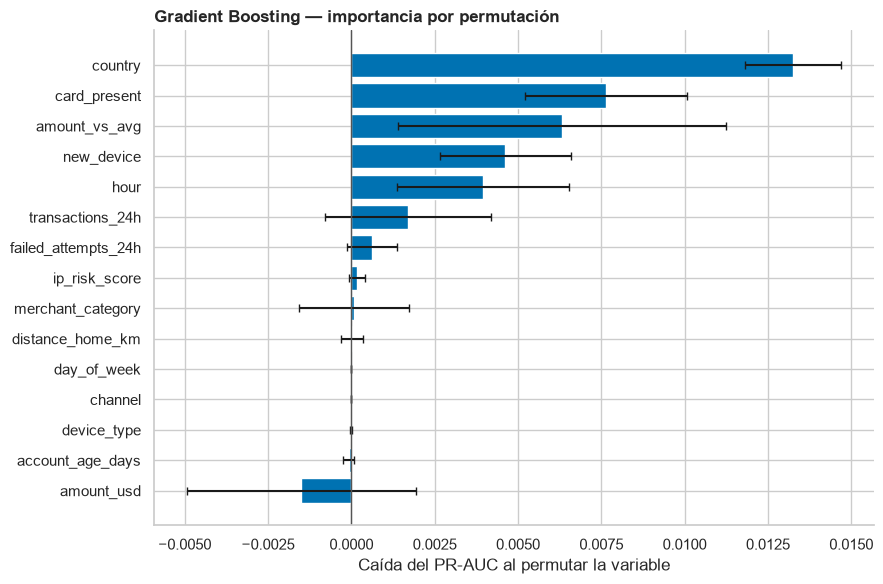

In [21]:
imp = importancia.sort_values("caída PR-AUC")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp["caída PR-AUC"], xerr=imp["desv."], color="#0072B2", capsize=3)
ax.axvline(0, color="#555", lw=1)
ax.set(xlabel="Caída del PR-AUC al permutar la variable", ylabel="")
ax.set_title("Gradient Boosting — importancia por permutación", loc="left", fontweight="bold")
sns.despine()
guardar("gb_importancia")

## 7. Guardado

Se guarda la versión final (la de mayor PR-AUC en CV) ajustada en todo train, con sus métricas de CV y sus probabilidades fuera de fold para la comparación final.

In [22]:
guardar_resultados("gradient_boosting", mejor.best_estimator_, resumen_cv(mejor), y, oof_mejor)

['cv_gradient_boosting.csv',
 'gradient_boosting.joblib',
 'oof_gradient_boosting.csv']

## 8. Conclusiones

- **Modelo final:** Gradient Boosting mejorado con tocones (árboles de profundidad 1), tasa de aprendizaje 0.03, 400 iteraciones, hoja mínima 50 y peso de fraude ×10.
- **Rendimiento en CV (media ± desviación):** PR-AUC 0.062 ± 0.007 y ROC-AUC 0.706 ± 0.020, el mejor de todos los modelos; prácticamente sin sobreajuste (PR-AUC train 0.066, cociente train/validación 1.07 frente a 1.53 del base).
- **Hallazgo clave:** los tocones, que no pueden combinar variables, superan a los árboles más profundos. La señal es **aditiva**: cada variable aporta al riesgo por separado y no hay interacciones que aprender, lo que es coherente con datos generados sintéticamente con una fórmula.
- **Con el umbral óptimo de F1 (0.33):** alerta el 3.2% de las transacciones con precisión del 8.4%, sensibilidad del 14.7% y F1 de 0.107 (107 fraudes detectados, 620 no detectados, 1,165 falsas alarmas).
- **Según capacidad de revisión:** revisando el 1% de mayor riesgo la precisión llega al 10%; revisando el 10% detecta el 32% de los fraudes con precisión del 5.8%.
- **Variables más influyentes (permutación):** country, card_present, amount_vs_avg, new_device y hour; channel no aporta por separado porque su información ya la recoge card_present.
- **Lectura:** es el mejor modelo, pero su ventaja sobre Random Forest (0.057) y la Regresión Logística (0.051) es pequeña frente a la variación entre folds, y su precisión sigue lejos de la necesaria para un sistema antifraude real.